# Fashion-MNIST: Random Forest, Overfitting, and Feature Importance

**Aditya · Milestone 3 · Team T112**
*Project 11: Inventory Image Tagging via Handcrafted Features and a Small CNN*

Model 3 of the Phase 1 AML baseline. A Random Forest is trained on both feature sets from Milestone 2, **flattened pixels (784)** and **HOG descriptors (324)**. Each tree is a sequence of axis-aligned splits. The forest averages the trees, so it can represent interactions (a bright pixel only matters when another pixel is dark) that a linear model cannot. Tree depth controls how specific those interactions are allowed to become.

**Questions this notebook answers:**
1. How do `n_estimators` $\in \{50, 100, 200\}$ and `max_depth` $\in \{10, 20, \text{None}\}$ trade training fit against validation fit?
2. Does removing the depth limit memorize the training split while validation accuracy flattens?
3. Which pixel locations, and which HOG gradient-orientation blocks, receive the most Gini (mean decrease in impurity) importance?

**Protocol (shared across all four models):**
1. Tune on the stratified 48,000/12,000 development split (seed 42) and select by **validation macro F1**.
2. Refit the selected forest on all 60,000 training images.
3. Evaluate once on the official 10,000-image test set and export `reports/results/rf_{pixels,hog}.json`.

The test set is not used for any choice in this notebook.


In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
import numpy as np
import pandas as pd
from IPython.display import display

ROOT = next(
    (p for p in (Path.cwd(), *Path.cwd().parents)
     if (p / "pyproject.toml").is_file() and (p / "docs/team").is_dir()),
    None,
)
if ROOT is None:
    raise RuntimeError("Open this notebook from the repository root or notebooks/ directory.")
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

from aml.data import CLASS_NAMES, get_train_val_test_splits
from aml.features import get_features
from aml.models.random_forest import (
    MAX_DEPTH_GRID, N_ESTIMATORS_GRID, build_rf_pipeline, evaluate_final_rf,
    make_result_record, save_result, tune_rf,
)

CACHE_DIR = ROOT / "data" / "cache"
RESULTS_DIR = ROOT / "reports" / "results"
FIGURES_DIR = ROOT / "reports" / "figures" / "rf"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

FEATURE_LABELS = {"pixels": "Pixels", "hog": "HOG"}
DEPTH_ORDER = (10, 20, None)
DEPTH_TICKS = ["10", "20", "None"]
TREE_COLORS = {50: "#1b4f72", 100: "#0e7c66", 200: "#b9770e"}
# HOG layout used by aml.features: 3x3 blocks, 2x2 cells, 9 unsigned orientations.
HOG_SHAPE = (3, 3, 2, 2, 9)
CELL_PX = 7

plt.rcParams.update({"figure.dpi": 120, "axes.spines.top": False, "axes.spines.right": False})
print("Project root:", ROOT)
probe = build_rf_pipeline()
print(f"RandomForestClassifier n_jobs={probe.n_jobs}, random_state={probe.random_state}")


Matplotlib is building the font cache; this may take a moment.


Project root: /Users/adityainnovates/Desktop/Projects/tools/Image-Tagging
RandomForestClassifier n_jobs=-1, random_state=42


## 1. Load splits and cached features

Features come from `aml.features.get_features`. The first run extracts them and writes `data/cache/*.npz`; later runs load the cache. Pixels are the $28 \times 28$ image flattened to 784 values in $[0, 1]$. HOG uses 9 orientations, $7 \times 7$ pixels per cell, $2 \times 2$ cells per block, and L2-Hys normalization (324 values).


In [2]:
splits = get_train_val_test_splits(data_dir=ROOT / "data" / "raw")
y_train, y_val = splits["y_train"], splits["y_val"]
y_train_full, y_test = splits["y_train_full"], splits["y_test"]

features = {}
for kind in FEATURE_LABELS:
    features[kind] = {
        split: get_features(splits[f"X_{split}"], kind, CACHE_DIR / f"{split}_{kind}.npz")
        for split in ("train", "val", "test", "train_full")
    }
    shapes = ", ".join(f"{split} {X.shape}" for split, X in features[kind].items())
    print(f"{FEATURE_LABELS[kind]:>6}: {shapes}")


Pixels: train (48000, 784), val (12000, 784), test (10000, 784), train_full (60000, 784)


   HOG: train (48000, 324), val (12000, 324), test (10000, 324), train_full (60000, 324)


## 2. Tune tree count and depth

Each candidate is a Gini forest (`random_state=42`, `n_jobs=-1`). The grid is the Cartesian product of `n_estimators` $\in \{50, 100, 200\}$ and `max_depth` $\in \{10, 20, \text{None}\}$. `max_depth=None` grows each tree until leaves are pure (or smaller than `min_samples_split`). Training and validation accuracy are both recorded so the next section can plot the generalization gap. The kept setting is the highest **validation macro F1**. An exact tie keeps the earlier candidate.


In [3]:
tuning, best_params = {}, {}
for kind in FEATURE_LABELS:
    X = features[kind]
    print(f"--- {FEATURE_LABELS[kind]} ---")
    best_params[kind], tuning[kind] = tune_rf(
        X["train"], y_train, X["val"], y_val,
        n_estimators_grid=N_ESTIMATORS_GRID,
        max_depth_grid=MAX_DEPTH_GRID,
    )
    chosen = best_params[kind]
    print(
        f"Selected for {FEATURE_LABELS[kind]}: "
        f"n_estimators={chosen['n_estimators']}, max_depth={chosen['max_depth']}"
    )

tuning_table = pd.DataFrame([{
    "Features": FEATURE_LABELS[kind],
    "Trees": result["n_estimators"],
    "Max Depth": "None" if result["max_depth"] is None else result["max_depth"],
    "Train Accuracy": result["train_accuracy"],
    "Train Macro F1": result["train_macro_f1"],
    "Val Accuracy": result["val_accuracy"],
    "Val Macro F1": result["val_macro_f1"],
    "Selected": "✓" if (
        result["n_estimators"] == best_params[kind]["n_estimators"]
        and result["max_depth"] == best_params[kind]["max_depth"]
    ) else "",
} for kind in FEATURE_LABELS for result in tuning[kind]])
display(tuning_table.style.format({
    "Train Accuracy": "{:.2%}", "Train Macro F1": "{:.2%}",
    "Val Accuracy": "{:.2%}", "Val Macro F1": "{:.2%}",
}).hide(axis="index"))


--- Pixels ---
Training Random Forest: n_estimators=50, max_depth=10...


Training Random Forest: n_estimators=50, max_depth=20...


Training Random Forest: n_estimators=50, max_depth=None...


Training Random Forest: n_estimators=100, max_depth=10...


Training Random Forest: n_estimators=100, max_depth=20...


...

Training Random Forest: n_estimators=200, max_depth=10...


Training Random Forest: n_estimators=200, max_depth=20...


Training Random Forest: n_estimators=200, max_depth=None...


Selected for HOG: n_estimators=200, max_depth=None


Features,Trees,Max Depth,Train Accuracy,Train Macro F1,Val Accuracy,Val Macro F1,Selected
Pixels,50,10,88.45%,88.26%,85.47%,85.23%,
Pixels,50,20,99.34%,99.34%,87.88%,87.76%,
Pixels,50,None,100.00%,100.00%,88.03%,87.92%,
Pixels,100,10,88.45%,88.26%,85.48%,85.25%,
Pixels,100,20,99.41%,99.41%,88.33%,88.21%,
Pixels,100,None,100.00%,100.00%,88.12%,88.01%,
Pixels,200,10,88.67%,88.49%,85.78%,85.55%,
Pixels,200,20,99.42%,99.42%,88.57%,88.45%,✓
Pixels,200,None,100.00%,100.00%,88.38%,88.28%,
HOG,50,10,85.84%,85.81%,81.33%,81.26%,


## 3. Overfitting across tree depth

The plot compares training accuracy (dashed) with validation accuracy (solid) at depths 10, 20, and None. Color is the number of trees. Depth 10 underfits relative to a deeper forest: the leaves are still mixed, so both curves sit lower. Depth 20 closes most of the useful gap. Unlimited depth lets each tree keep splitting until it isolates training rows. Those extra splits fit idiosyncrasies of the 48,000 training images (exact stroke positions, pixel noise) that do not repeat in the validation split, so the dashed curve rises further while the solid curve flattens. That vertical gap is the bias-variance tradeoff. The model that is kept is the one with the best validation macro F1, not the one with the highest training score.


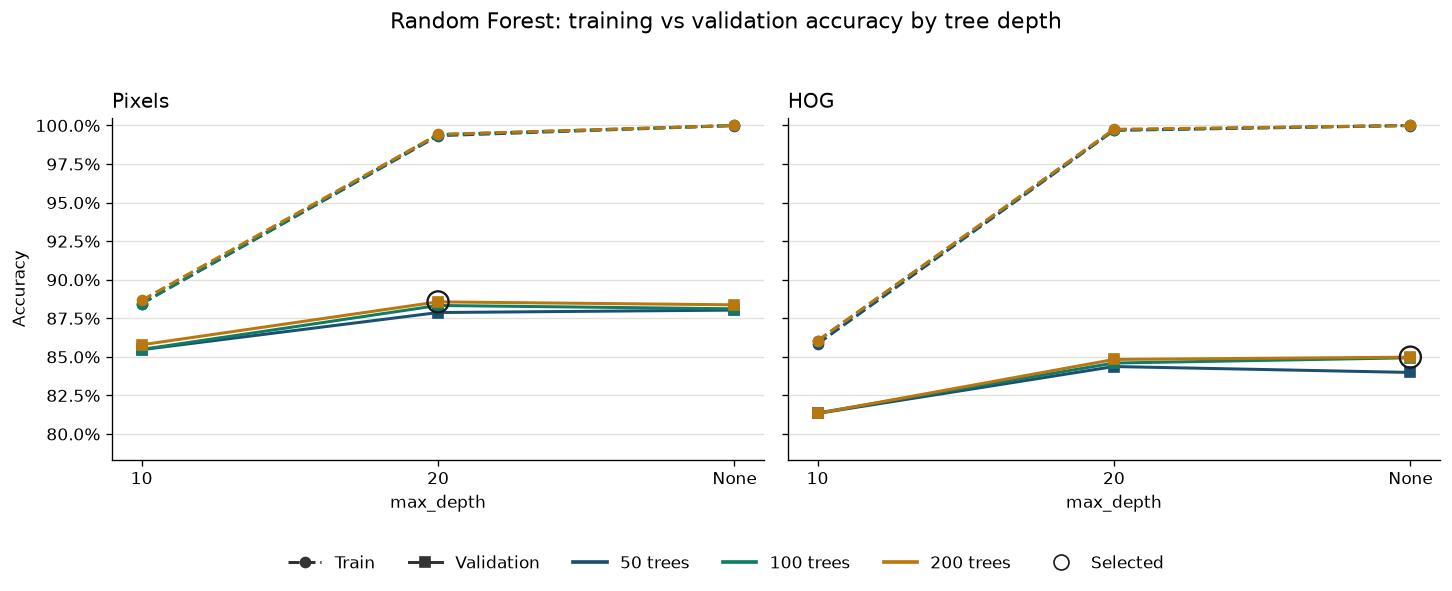

Generalization gap at max_depth=None (train accuracy − validation accuracy):
  Pixels:
     50 trees  train 100.00%  val 88.03%  gap 11.96%
    100 trees  train 100.00%  val 88.12%  gap 11.88%
    200 trees  train 100.00%  val 88.38%  gap 11.62%
  HOG:
     50 trees  train 100.00%  val 83.99%  gap 16.01%
    100 trees  train 100.00%  val 84.94%  gap 15.06%
    200 trees  train 100.00%  val 84.98%  gap 15.02%


In [4]:
from matplotlib.lines import Line2D

fig, axes = plt.subplots(1, 2, figsize=(12.2, 4.8), sharey=True)
observed = []
for ax, kind in zip(axes, FEATURE_LABELS):
    by_key = {(row["n_estimators"], row["max_depth"]): row for row in tuning[kind]}
    for n_estimators, color in TREE_COLORS.items():
        train = [by_key[(n_estimators, depth)]["train_accuracy"] for depth in DEPTH_ORDER]
        val = [by_key[(n_estimators, depth)]["val_accuracy"] for depth in DEPTH_ORDER]
        observed.extend(train)
        observed.extend(val)
        ax.plot(DEPTH_TICKS, train, linestyle="--", marker="o", color=color, linewidth=1.8)
        ax.plot(DEPTH_TICKS, val, linestyle="-", marker="s", color=color, linewidth=1.8)
    chosen = best_params[kind]
    chosen_depth = "None" if chosen["max_depth"] is None else str(chosen["max_depth"])
    chosen_row = next(
        row for row in tuning[kind]
        if row["n_estimators"] == chosen["n_estimators"] and row["max_depth"] == chosen["max_depth"]
    )
    ax.scatter(
        [chosen_depth], [chosen_row["val_accuracy"]],
        s=160, facecolors="none", edgecolors="#1a1a1a", linewidths=1.4, zorder=5,
    )
    ax.set_title(FEATURE_LABELS[kind], loc="left")
    ax.set_xlabel("max_depth")
    ax.yaxis.set_major_formatter(PercentFormatter(1))
    ax.grid(axis="y", color="#e1e0d9", linewidth=0.8)
    ax.set_axisbelow(True)

axes[0].set_ylabel("Accuracy")
axes[0].set_ylim(min(observed) - 0.03, 1.005)
legend_handles = [
    Line2D([0], [0], color="#333333", lw=1.8, linestyle="--", marker="o", label="Train"),
    Line2D([0], [0], color="#333333", lw=1.8, linestyle="-", marker="s", label="Validation"),
    *[Line2D([0], [0], color=color, lw=2.2, label=f"{n_estimators} trees")
      for n_estimators, color in TREE_COLORS.items()],
    Line2D([0], [0], marker="o", color="none", markerfacecolor="none",
           markeredgecolor="#1a1a1a", markersize=9, label="Selected"),
]
fig.legend(handles=legend_handles, loc="lower center", ncol=6, frameon=False,
           bbox_to_anchor=(0.5, -0.02))
fig.suptitle("Random Forest: training vs validation accuracy by tree depth", fontsize=13)
fig.tight_layout(rect=(0, 0.08, 1, 0.94))
fig.savefig(FIGURES_DIR / "overfitting_curves.png", dpi=300, bbox_inches="tight")
plt.show()

print("Generalization gap at max_depth=None (train accuracy − validation accuracy):")
for kind in FEATURE_LABELS:
    print(f"  {FEATURE_LABELS[kind]}:")
    for row in tuning[kind]:
        if row["max_depth"] is not None:
            continue
        gap = row["train_accuracy"] - row["val_accuracy"]
        print(
            f"    {row['n_estimators']:>3} trees  "
            f"train {row['train_accuracy']:.2%}  val {row['val_accuracy']:.2%}  gap {gap:.2%}"
        )


## 4. Refit on 60,000 images and evaluate on the test set

The selected `(n_estimators, max_depth)` for each feature set is refit on the full official training set. Latency is the median per-image `predict()` time on a 1,000-image batch. Feature extraction is excluded. `parameter_count` is the total number of nodes across every tree, which is how the shared schema records forest complexity.


In [5]:
models, test_metrics, records = {}, {}, {}
for kind in FEATURE_LABELS:
    X = features[kind]
    models[kind], test_metrics[kind], latency_ms, total_nodes = evaluate_final_rf(
        X["train_full"], y_train_full, X["test"], y_test, best_params[kind],
    )
    records[kind] = make_result_record(
        kind, best_params[kind], tuning[kind], test_metrics[kind], latency_ms, total_nodes,
        train_n=len(y_train), val_n=len(y_val), test_n=len(y_test),
    )
    print(f"Saved {save_result(records[kind], RESULTS_DIR).relative_to(ROOT)}")

summary = pd.DataFrame([{
    "Features": FEATURE_LABELS[kind],
    "Trees": record["best_params"]["n_estimators"],
    "Max Depth": "None" if record["best_params"]["max_depth"] is None else record["best_params"]["max_depth"],
    "Val Accuracy": record["validation_accuracy"],
    "Val Macro F1": record["validation_macro_f1"],
    "Test Accuracy": record["test_accuracy"],
    "Test Macro F1": record["test_macro_f1"],
    "Nodes": record["parameter_count"],
    "Latency (ms/img)": record["inference_latency_ms_per_image"],
} for kind, record in records.items()])
display(summary.style.format({
    "Val Accuracy": "{:.2%}", "Val Macro F1": "{:.2%}",
    "Test Accuracy": "{:.2%}", "Test Macro F1": "{:.2%}",
    "Nodes": "{:,}", "Latency (ms/img)": "{:.4f}",
}).hide(axis="index"))

recall = pd.DataFrame(
    {FEATURE_LABELS[kind]: records[kind]["per_class_recall"] for kind in FEATURE_LABELS},
    index=CLASS_NAMES,
)
display(recall.style.format("{:.1%}").set_caption("Test recall"))

for kind in FEATURE_LABELS:
    matrix = np.asarray(records[kind]["test_confusion_matrix"])
    errors = matrix - np.diag(np.diag(matrix))
    print(f"{FEATURE_LABELS[kind]} largest confusions:")
    for flat in np.argsort(errors, axis=None)[::-1][:5]:
        true, pred = divmod(int(flat), 10)
        print(f"  {CLASS_NAMES[true]:>11} → {CLASS_NAMES[pred]:<11} {errors[true, pred]:4d}")


Saved reports/results/rf_pixels.json


Saved reports/results/rf_hog.json


Features,Trees,Max Depth,Val Accuracy,Val Macro F1,Test Accuracy,Test Macro F1,Nodes,Latency (ms/img)
Pixels,200,20,88.57%,88.45%,87.43%,87.31%,"1,693,570",0.0264
HOG,200,None,84.98%,84.91%,84.35%,84.30%,"2,458,016",0.0291


,Pixels,HOG
T-shirt/top,85.9%,81.2%
Trouser,96.1%,92.6%
Pullover,78.9%,73.6%
Dress,90.5%,85.5%
Coat,81.1%,74.7%
Sandal,95.6%,94.0%
Shirt,59.3%,59.4%
Sneaker,95.2%,90.8%
Bag,97.3%,96.9%
Ankle boot,94.4%,94.8%


Pixels largest confusions:
        Shirt → T-shirt/top  148
     Pullover → Coat         130
        Shirt → Pullover     120
         Coat → Pullover      93
        Shirt → Coat          90
HOG largest confusions:
        Shirt → T-shirt/top  149
     Pullover → Coat         139
         Coat → Pullover     121
        Shirt → Coat         102
     Pullover → Shirt        101


## 5. Gini feature importance

`feature_importances_` is the mean decrease in Gini impurity, normalized to sum to 1. A feature ranks high when trees often split on it and those splits separate the classes. It is not a causal map, and correlated neighbors (adjacent pixels, overlapping HOG blocks) share credit, but the spatial pattern shows where the forest looks.

**Pixels.** The 784 importances are reshaped to $28 \times 28$. Mass away from the black border means the splits use the garment body: the torso, the gap between trouser legs, and the sole and shaft of shoes.

**HOG.** The 324 descriptor follows scikit-image's block layout `(3 block rows, 3 block columns, 2 cell rows, 2 cell columns, 9 orientations)`. Each block covers a $14 \times 14$ window and the next block steps by one $7 \times 7$ cell, so neighboring blocks overlap. Orientations are unsigned, in $20^\circ$ bins from $0^\circ$ to $160^\circ$. The block heatmap sums importance inside each window. The bars sum importance by orientation across the whole image.


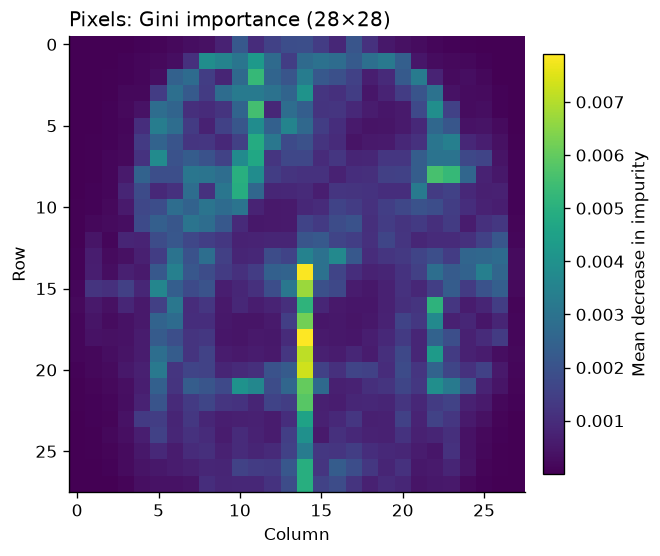

Pixel importance sums to 1.0000.
Top 5% of pixels span rows 1–27, cols 5–23 (centroid row 12.8, col 13.7).
  2px border: 13.6% of total importance
  center torso (rows 6–18, cols 8–19): 24.9% of total importance
  leg gap (rows 8–22, cols 12–15): 13.2% of total importance
  lower band (rows 20–27): 23.9% of total importance


In [6]:
pixel_importance = np.asarray(models["pixels"].feature_importances_, dtype=np.float64)
if pixel_importance.shape != (784,):
    raise ValueError(f"Expected 784 pixel importances, got {pixel_importance.shape}.")
heatmap = pixel_importance.reshape(28, 28)

fig, ax = plt.subplots(figsize=(5.4, 4.8), constrained_layout=True)
image = ax.imshow(heatmap, cmap="viridis")
ax.set_title("Pixels: Gini importance (28×28)", loc="left")
ax.set_xlabel("Column")
ax.set_ylabel("Row")
colorbar = fig.colorbar(image, ax=ax, fraction=0.046, pad=0.04)
colorbar.set_label("Mean decrease in impurity")
fig.savefig(FIGURES_DIR / "pixel_importance_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()

border = np.zeros((28, 28), dtype=bool)
border[:2, :] = True
border[-2:, :] = True
border[:, :2] = True
border[:, -2:] = True
regions = {
    "2px border": border,
    "center torso (rows 6–18, cols 8–19)": np.zeros((28, 28), dtype=bool),
    "leg gap (rows 8–22, cols 12–15)": np.zeros((28, 28), dtype=bool),
    "lower band (rows 20–27)": np.zeros((28, 28), dtype=bool),
}
regions["center torso (rows 6–18, cols 8–19)"][6:19, 8:20] = True
regions["leg gap (rows 8–22, cols 12–15)"][8:23, 12:16] = True
regions["lower band (rows 20–27)"][20:, :] = True
hot = heatmap >= np.quantile(heatmap, 0.95)
hot_rows, hot_cols = np.where(hot)
print(f"Pixel importance sums to {pixel_importance.sum():.4f}.")
print(
    f"Top 5% of pixels span rows {hot_rows.min()}–{hot_rows.max()}, "
    f"cols {hot_cols.min()}–{hot_cols.max()} "
    f"(centroid row {hot_rows.mean():.1f}, col {hot_cols.mean():.1f})."
)
for name, mask in regions.items():
    print(f"  {name}: {heatmap[mask].sum():.1%} of total importance")


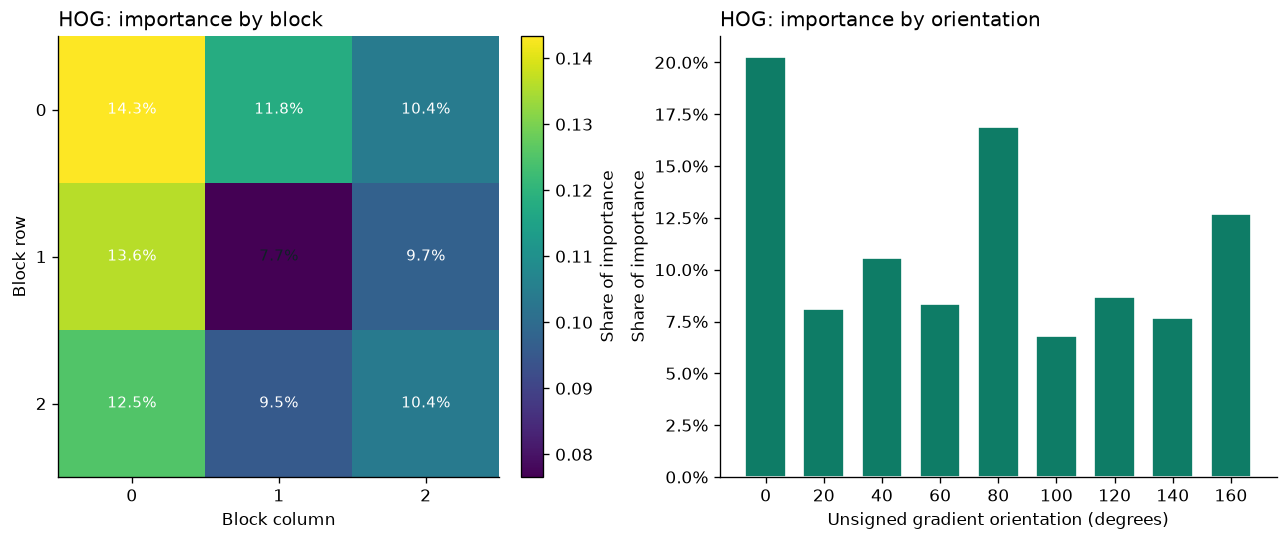

HOG importance sums to 1.0000.
Blocks ranked by total Gini importance (each block is a 14×14 window, stride 7):
  1. block (0, 0)  pixels rows 0–14, cols 0–14  share 14.3%  dominant orientation 0°
  2. block (1, 0)  pixels rows 7–21, cols 0–14  share 13.6%  dominant orientation 0°
  3. block (2, 0)  pixels rows 14–28, cols 0–14  share 12.5%  dominant orientation 0°
  4. block (0, 1)  pixels rows 0–14, cols 7–21  share 11.8%  dominant orientation 80°
  5. block (0, 2)  pixels rows 0–14, cols 14–28  share 10.4%  dominant orientation 80°
  6. block (2, 2)  pixels rows 14–28, cols 14–28  share 10.4%  dominant orientation 0°
  7. block (1, 2)  pixels rows 7–21, cols 14–28  share 9.7%  dominant orientation 0°
  8. block (2, 1)  pixels rows 14–28, cols 7–21  share 9.5%  dominant orientation 80°
  9. block (1, 1)  pixels rows 7–21, cols 7–21  share 7.7%  dominant orientation 40°
Strongest orientations overall: 0° (20.3%), 80° (16.9%), 160° (12.7%)


In [7]:
hog_importance = np.asarray(models["hog"].feature_importances_, dtype=np.float64)
if hog_importance.shape != (324,):
    raise ValueError(f"Expected 324 HOG importances, got {hog_importance.shape}.")
blocks = hog_importance.reshape(HOG_SHAPE)
block_mass = blocks.sum(axis=(2, 3, 4))
orientation_mass = blocks.sum(axis=(0, 1, 2, 3))
orientation_degrees = np.arange(9) * 20

fig, axes = plt.subplots(1, 2, figsize=(11.2, 4.4), constrained_layout=True)
block_image = axes[0].imshow(block_mass, cmap="viridis")
axes[0].set_title("HOG: importance by block", loc="left")
axes[0].set_xlabel("Block column")
axes[0].set_ylabel("Block row")
axes[0].set_xticks(range(3))
axes[0].set_yticks(range(3))
for row in range(3):
    for col in range(3):
        axes[0].text(col, row, f"{block_mass[row, col]:.1%}", ha="center", va="center",
                     color="white" if block_mass[row, col] > block_mass.max() * 0.55 else "#102026",
                     fontsize=9)
fig.colorbar(block_image, ax=axes[0], fraction=0.046, pad=0.04, label="Share of importance")

axes[1].bar(orientation_degrees, orientation_mass, width=14, color="#0e7c66", edgecolor="white")
axes[1].set_title("HOG: importance by orientation", loc="left")
axes[1].set_xlabel("Unsigned gradient orientation (degrees)")
axes[1].set_ylabel("Share of importance")
axes[1].set_xticks(orientation_degrees)
axes[1].yaxis.set_major_formatter(PercentFormatter(1))
fig.savefig(FIGURES_DIR / "hog_importance.png", dpi=300, bbox_inches="tight")
plt.show()

order = np.argsort(block_mass, axis=None)[::-1]
print(f"HOG importance sums to {hog_importance.sum():.4f}.")
print("Blocks ranked by total Gini importance (each block is a 14×14 window, stride 7):")
for rank, flat in enumerate(order, start=1):
    block_row, block_col = divmod(int(flat), 3)
    cell_orientation = blocks[block_row, block_col].sum(axis=(0, 1))
    dominant = int(cell_orientation.argmax())
    r0, c0 = block_row * CELL_PX, block_col * CELL_PX
    print(
        f"  {rank}. block ({block_row}, {block_col})  "
        f"pixels rows {r0}–{r0 + 14}, cols {c0}–{c0 + 14}  "
        f"share {block_mass[block_row, block_col]:.1%}  "
        f"dominant orientation {dominant * 20}°"
    )
print(
    "Strongest orientations overall: "
    + ", ".join(f"{int(deg)}° ({orientation_mass[int(deg) // 20]:.1%})"
                for deg in orientation_degrees[np.argsort(orientation_mass)[::-1][:3]])
)


## 6. Verify outputs

These checks match the acceptance checklist and the master notebook's result schema. `parameter_count` must be an integer node count. Development sizes stay at 48,000 / 12,000 / 10,000.


In [8]:
REQUIRED = {
    "model", "features", "best_params", "train_n", "val_n", "test_n",
    "validation_accuracy", "validation_macro_f1", "test_accuracy", "test_macro_f1",
    "per_class_recall", "parameter_count", "inference_latency_ms_per_image",
}
built = build_rf_pipeline()
assert built.n_jobs == -1
assert built.random_state == 42

for kind in FEATURE_LABELS:
    assert len(tuning[kind]) == len(N_ESTIMATORS_GRID) * len(MAX_DEPTH_GRID)
    assert [row["n_estimators"] for row in tuning[kind]] == [
        n for n in N_ESTIMATORS_GRID for _ in MAX_DEPTH_GRID
    ]
    assert [row["max_depth"] for row in tuning[kind]] == [
        depth for _ in N_ESTIMATORS_GRID for depth in MAX_DEPTH_GRID
    ]
    unlimited = [row for row in tuning[kind] if row["max_depth"] is None]
    assert unlimited, kind
    assert max(row["train_accuracy"] for row in unlimited) > max(row["val_accuracy"] for row in unlimited)

    saved = json.loads((RESULTS_DIR / f"rf_{kind}.json").read_text())
    assert REQUIRED <= saved.keys(), REQUIRED - saved.keys()
    assert (saved["model"], saved["features"]) == ("rf", kind)
    assert (saved["train_n"], saved["val_n"], saved["test_n"]) == (48000, 12000, 10000)
    assert all(0 <= saved[key] <= 1 for key in (
        "validation_accuracy", "validation_macro_f1", "test_accuracy", "test_macro_f1",
    ))
    assert len(saved["per_class_recall"]) == 10
    assert all(0 <= value <= 1 for value in saved["per_class_recall"])
    assert isinstance(saved["parameter_count"], int) and saved["parameter_count"] > 0
    assert saved["parameter_count"] % 1 == 0
    assert saved["inference_latency_ms_per_image"] > 0
    assert set(saved["best_params"]) == {"n_estimators", "max_depth"}
    assert saved["best_params"]["n_estimators"] in N_ESTIMATORS_GRID
    assert saved["best_params"]["max_depth"] in MAX_DEPTH_GRID
    assert np.asarray(saved["test_confusion_matrix"]).shape == (10, 10)
    assert models[kind].n_jobs == -1

for name in ("overfitting_curves.png", "pixel_importance_heatmap.png", "hog_importance.png"):
    path = FIGURES_DIR / name
    assert path.is_file() and path.stat().st_size > 0, name

assert models["pixels"].feature_importances_.shape == (784,)
assert models["hog"].feature_importances_.shape == (324,)
print("All checks passed: both JSON reports match the schema, and the depth sweep shows a train/validation gap.")


All checks passed: both JSON reports match the schema, and the depth sweep shows a train/validation gap.


## 7. Summary

Unlimited depth memorizes the 48,000-image training split. At `max_depth=None`, training accuracy is **100.00%** for every tree count on both feature sets. Validation accuracy does not follow it.

| | 50 trees | 100 trees | 200 trees |
|---|---:|---:|---:|
| Pixels validation accuracy at `max_depth=None` | 88.03% | 88.12% | 88.38% |
| Pixels gap (train − val) | 11.96% | 11.88% | 11.62% |
| HOG validation accuracy at `max_depth=None` | 83.99% | 84.94% | 84.98% |
| HOG gap (train − val) | 16.01% | 15.06% | 15.02% |

Depth 10 sits lower on both the training and validation curves. Depth 20 is where validation stops improving in any useful way. Past that point the forest spends new splits on training idiosyncrasies. Selection uses validation macro F1, not training accuracy:

- **Pixels:** 200 trees, `max_depth=20`. Validation accuracy 88.57%, validation macro F1 88.45%. Test accuracy 87.43%, test macro F1 87.31%. The refit forest has 1,693,570 nodes.
- **HOG:** 200 trees, `max_depth=None`. Validation accuracy 84.98%, validation macro F1 84.91%. Test accuracy 84.35%, test macro F1 84.30%. The refit forest has 2,458,016 nodes, more than the pixel forest, because the trees were grown without a depth limit.

Pixels is the stronger representation here, by about 3 points of test macro F1. Both predict in about 0.03 ms per image on a 1,000-image batch.

**Where the pixel forest looks.** The 28×28 Gini map is dark in the empty border (the outer 2 pixels are 26% of the locations and only 13.6% of the importance). The brightest structure is a vertical stripe around column 14, from about row 14 to the bottom edge: that is the gap between trouser legs and the boundary that separates a narrow garment from a wide one. Above it, importance follows the shoulder and sleeve line. The lower rows (20–27) hold 23.9% of the importance, which is the shoe sole and shaft. The center of the torso is used, but it is not the brightest region; the splits prefer the contours.

**Where the HOG forest looks.** Importance is highest in the outer blocks and lowest in the center block (7.7%, rows 7–21 and columns 7–21). The left column of blocks, covering pixel columns 0–14, is the strongest (14.3%, 13.6%, and 12.5%). Unsigned orientation 0° takes 20.3% of the importance. That bin is a horizontal gradient, which fires on vertical edges: sleeve sides, trouser legs, and the outer silhouette. 80° (16.9%) is close to a vertical gradient, so it fires on horizontal edges such as hems and shoe soles. 160° (12.7%) sits next to the 0° bin and picks up the same vertical boundaries. Together those three bins are about half of the descriptor.

**The same upper-body confusion remains.** Shirt test recall is 59.3% on pixels and 59.4% on HOG. The largest off-diagonal counts are Shirt → T-shirt/top (148 pixels, 149 HOG), Pullover → Coat (130 and 139), and Coat → Pullover. Trouser (96.1% pixel recall) and Bag (97.3%) are easy because their silhouette is not shared. Axis-aligned splits, whether on pixels or on fixed HOG blocks, do not build a detector for a collar or a placket that can sit a few pixels higher or lower. That is the gap Phase 2's convolutional network is meant to close.

**Outputs:** `reports/results/rf_pixels.json`, `reports/results/rf_hog.json`, `reports/figures/rf/overfitting_curves.png`, `reports/figures/rf/pixel_importance_heatmap.png`, and `reports/figures/rf/hog_importance.png`.
